# AstroRestore AI en Google Colab

La autora registró una prueba de difusión en Tesla T4; el acceso a Gradio remoto sigue pendiente de verificación. Ejecuta la celda auxiliar de salida antes de los subprocesos para ver los registros desde VS Code. En Entorno de ejecución > Cambiar tipo de entorno de ejecución, selecciona GPU (por ejemplo T4 si está disponible). Las celdas detendrán la ejecución si no hay GPU accesible.

Selecciona un entorno con GPU. La interfaz permite subir una imagen y ejecutar una prueba de difusión imagen a imagen; la primera ejecución descarga varios GB de pesos. La prueba todavía no demuestra reducción de ruido. La disponibilidad de GPU no está garantizada.

In [17]:
import os
import signal
import subprocess

def ejecutar_con_salida(comando, cwd=None):
    """Muestra stdout y stderr del proceso en la salida de la celda de VS Code."""
    entorno = os.environ.copy()
    entorno['PYTHONUNBUFFERED'] = '1'
    print('Proceso iniciado. Los mensajes aparecerán debajo de esta celda.', flush=True)
    with subprocess.Popen(
        comando, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding='utf-8', errors='replace', bufsize=1, env=entorno,
        start_new_session=(os.name == 'posix'),
    ) as proceso:
        try:
            for linea in proceso.stdout:
                print(linea, end='', flush=True)
            codigo = proceso.wait()
        except KeyboardInterrupt:
            if proceso.poll() is None:
                if os.name == 'posix':
                    os.killpg(proceso.pid, signal.SIGTERM)
                else:
                    proceso.terminate()
                try:
                    proceso.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    if os.name == 'posix':
                        os.killpg(proceso.pid, signal.SIGKILL)
                    else:
                        proceso.kill()
                    proceso.wait()
            raise
    if codigo != 0:
        raise subprocess.CalledProcessError(codigo, comando)
    print('Proceso finalizado correctamente.', flush=True)


In [18]:
from pathlib import Path
import subprocess
import sys
import shutil

if not Path('/content').is_dir():
    raise RuntimeError('Este notebook está preparado para Google Colab.')
if shutil.which('nvidia-smi') is None:
    raise RuntimeError('Selecciona un entorno GPU en Colab antes de ejecutar las celdas.')
gpu = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
if gpu.returncode != 0:
    raise RuntimeError('No hay GPU NVIDIA disponible. Selecciona un entorno GPU y vuelve a ejecutar.')
print(gpu.stdout)

proyecto = Path('/content/astro-restauracion')
if not proyecto.exists():
    subprocess.run(['git', 'clone', 'https://github.com/Sabri-Nang/astro-restauracion.git', str(proyecto)], check=True)
revision = subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=proyecto, text=True).strip()
print('Revisión del proyecto:', revision)
if not (proyecto / 'app.py').is_file():
    raise RuntimeError('La versión remota todavía no contiene app.py. Publica primero la estructura actualizada.')
subprocess.run([sys.executable, '-m', 'pip', 'install', 'uv==0.12.3', 'ipywidgets==8.1.7'], check=True)
subprocess.run(['uv', 'sync', '--locked', '--python', '3.12'], cwd=proyecto, check=True)


Wed Nov 11 20:39:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

CompletedProcess(args=['uv', 'sync', '--locked', '--python', '3.12'], returncode=0)

In [19]:
ejecutar_con_salida(
    ['uv', 'run', '--locked', 'python', '-u', '-c',
     "import sys, torch; print('Python:', sys.version); print('PyTorch:', torch.__version__); assert sys.version_info[:2] == (3, 12), 'Se requiere Python 3.12'; assert torch.cuda.is_available(), 'PyTorch no puede acceder a CUDA: revisa el entorno GPU'; print('GPU:', torch.cuda.get_device_name(0)); print('VRAM (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))"],
    cwd=proyecto,
)
# Esta comprobación no valida la inferencia de un modelo de difusión.


Proceso iniciado. Los mensajes aparecerán debajo de esta celda.
Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
PyTorch: 2.15.0+cu132
GPU: Tesla T4
VRAM (GiB): 14.56
Proceso finalizado correctamente.


## Prueba del modelo (opcional antes de abrir la interfaz)
Selecciona primero el archivo local potw1803a.tif en el widget de la celda siguiente. La prueba utiliza ese archivo y verifica que sea el mismo original público de ESA/Hubble empleado en CPU. Si ya está verificado en esta sesión, lo reutiliza. La descarga automática es opcional (ORIGEN_IMAGEN = descargar); si falla, se solicita la subida manual. Usa exactamente la misma semilla, tamaño, intensidad y cantidad de pasos para comparar tiempos. Crédito: NASA, ESA, and J. Comerford (University of Colorado-Boulder). Fuente: https://esahubble.org/images/potw1803a/ — condiciones: https://esahubble.org/copyright/ (CC BY 4.0). Se generan una copia reducida y una salida generativa; no se modifica el TIFF. Una salida generada no prueba eliminación de ruido ni autenticidad científica.

### Seleccionar el TIFF antes de ejecutar la prueba
Ejecuta esta celda, pulsa **Subir TIFF** y selecciona `potw1803a.tif`. Espera a que termine la transferencia y ejecuta después la celda de prueba. El selector usa ipywidgets y funciona con el kernel remoto desde VS Code o Colab web; google.colab.files.upload no está soportado por la extensión de VS Code. Si no aparece el selector, comprueba que los widgets de Jupyter se rendericen en VS Code o abre el notebook en Colab web.


In [20]:
import ipywidgets as widgets
from IPython.display import display

cargador = widgets.FileUpload(accept='.tif,.tiff', multiple=False, description='Subir TIFF')
display(cargador)
print('Selecciona potw1803a.tif y espera a que termine la transferencia antes de ejecutar la siguiente celda.')


FileUpload(value={}, accept='.tif,.tiff', description='Subir TIFF')

Selecciona potw1803a.tif y espera a que termine la transferencia antes de ejecutar la siguiente celda.


Se reutiliza el TIFF verificado de esta sesión.
SHA-256 verificado: se usará la misma entrada que en CPU.
Proceso iniciado. Los mensajes aparecerán debajo de esta celda.
Modelo: stable-diffusion-v1-5/stable-diffusion-v1-5
Revisión: 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.

Loading pipeline components...:  29%|██▊       | 2/7 [00:00<00:01,  4.86it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 3777.00it/s]

Loading pipeline components...:  43%|████▎     | 3/7 [0

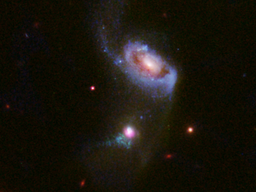

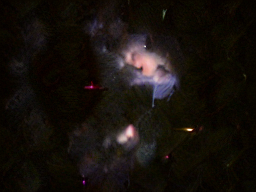

{
  "tipo": "prueba_tecnica_img2img_no_evaluacion_de_denoising",
  "modelo": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "revision": "451f4fe16113bff5a5d2269ed5ad43b0592e9a14",
  "licencia": "CreativeML OpenRAIL-M",
  "entrada": "potw1803a.tif",
  "sha256_entrada": "9bc563fef8171c749cc455ad9b0b140652cd26c28187eff4983686bf74f147a2",
  "dimensiones_preparadas": [
    256,
    192
  ],
  "preprocesamiento": "RGB 8 bits, LANCZOS, sin recorte, lados ajustados a múltiplos de 8",
  "ruido_artificial_agregado": false,
  "prompt": "astronomical photograph, stars and galaxies",
  "intensidad": 0.5,
  "pasos_configurados": 4,
  "pasos_efectivos": 2,
  "guidance_scale": 1.0,
  "semilla": 42,
  "scheduler": "DDIMScheduler",
  "dispositivo": "cuda:0",
  "precision": "torch.float16",
  "segundos_carga_o_acceso_cache_memoria": 10.533,
  "segundos_inferencia": 0.842,
  "python": "3.12.3",
  "sistema": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "versiones": {
    "torch": "2.15.0",
    "diffusers": 

In [21]:
from IPython.display import display, Image
import hashlib
import json
from urllib.request import urlopen

from urllib.error import URLError

# La subida local evita depender del servidor de descargas, que puede devolver 403.
ORIGEN_IMAGEN = 'subir'  # Alternativa opcional: 'descargar'.
HASH_ESPERADO = '9bc563fef8171c749cc455ad9b0b140652cd26c28187eff4983686bf74f147a2'
entrada = proyecto / 'assets/ejemplos/originales/potw1803a.tif'
entrada.parent.mkdir(parents=True, exist_ok=True)

if entrada.is_file() and hashlib.sha256(entrada.read_bytes()).hexdigest() == HASH_ESPERADO:
    contenido = entrada.read_bytes()
    print('Se reutiliza el TIFF verificado de esta sesión.')
else:
    contenido = None
    if ORIGEN_IMAGEN not in ('subir', 'descargar'):
        raise ValueError('ORIGEN_IMAGEN debe ser subir o descargar.')
    if ORIGEN_IMAGEN == 'descargar':
        try:
            with urlopen('https://esahubble.org/media/archives/images/original/potw1803a.tif', timeout=120) as respuesta:
                contenido = respuesta.read()
        except (URLError, TimeoutError, OSError) as error:
            print(f'No se pudo descargar automáticamente: {error}. Sube el TIFF local.')
    if contenido is None:
        if 'cargador' not in globals() or not cargador.value:
            raise ValueError('Ejecuta la celda Subir TIFF, selecciona potw1803a.tif y espera a que termine la transferencia.')
        elementos = tuple(cargador.value.values()) if isinstance(cargador.value, dict) else tuple(cargador.value)
        if len(elementos) != 1:
            raise ValueError('Selecciona exactamente un archivo: potw1803a.tif.')
        contenido = bytes(elementos[0]['content'])
    if hashlib.sha256(contenido).hexdigest() != HASH_ESPERADO:
        raise ValueError('El archivo no coincide con el TIFF de referencia. Sube potw1803a.tif sin conversiones ni modificaciones.')
    entrada.write_bytes(contenido)
print('SHA-256 verificado: se usará la misma entrada que en CPU.')
ejecutar_con_salida(
    ['uv', 'run', '--locked', 'python', '-u', '-m', 'src.diffusion',
     '--input', str(entrada), '--output-dir', 'outputs/prueba_colab',
     '--device', 'cuda', '--steps', '4', '--strength', '0.5', '--size', '256'],
    cwd=proyecto,
)
salidas = proyecto / 'outputs/prueba_colab'
display(Image(filename=str(salidas / 'entrada_preparada.png')))
display(Image(filename=str(salidas / 'salida.png')))
registro = json.loads((salidas / 'parametros.json').read_text(encoding='utf-8'))
registro['revision_proyecto'] = revision
registro['gpu_colab'] = gpu.stdout
(salidas / 'parametros.json').write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(registro, ensure_ascii=False, indent=2))
print('Referencia CPU local: 174.832 segundos de inferencia; comparar con segundos_inferencia de esta ejecución.')


## Descargar la prueba (opcional)
Descarga las dos imágenes y el registro antes de cerrar la sesión. Colab elimina los archivos temporales cuando finaliza el entorno.

In [14]:
from google.colab import files
import shutil

carpeta_resultados = proyecto / 'outputs/prueba_colab'
if not (carpeta_resultados / 'parametros.json').is_file():
    raise RuntimeError('Ejecuta primero la prueba del modelo.')
archivo_zip = shutil.make_archive('/content/astrorestore_prueba_colab', 'zip', carpeta_resultados)
files.download(archivo_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Abrir la interfaz
La siguiente celda mantendrá el servidor activo y solicitará un enlace público temporal de Gradio. Cualquier persona que tenga ese enlace podrá acceder mientras esté activo. Sube un PNG o TIFF de 8 bits desde la aplicación. La primera prueba en la interfaz volverá a cargar el modelo en ese proceso, reutilizando los pesos descargados. Interrumpe la celda al terminar. En el nivel gratuito, Colab puede terminar sesiones cuyo uso principal sea una interfaz web externa; prioriza las pruebas en las celdas del notebook. Consulta https://research.google.com/colaboratory/faq.html.

**Esta celda permanece ejecutándose mientras Gradio está activo: no debe terminar para poder usar la aplicación.** Espera el enlace `https://...gradio.live` en su salida y ábrelo en el navegador. La nueva celda `ejecutar_con_salida` debe ejecutarse antes para que los registros aparezcan en VS Code. Usa Interrupt solo cuando quieras detener el servidor.


In [22]:
ejecutar_con_salida(
    ['uv', 'run', '--locked', 'python', '-u', '-c',
     "import torch; assert torch.cuda.is_available(), 'No hay GPU CUDA disponible'; from app import create_app; create_app().launch(share=True, server_name='0.0.0.0')"],
    cwd=proyecto,
)


Proceso iniciado. Los mensajes aparecerán debajo de esta celda.
* Running on local URL:  http://0.0.0.0:7860
* Running on public URL: https://4c811acf5150088a6e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.

Loading pipeline components...:   0%|          | 0/7 [0

KeyboardInterrupt: 